In [3]:
from sqlalchemy import create_engine, text
import pandas as pd

engine = create_engine('postgresql://hanguellee@localhost:5432/olist')

with engine.connect() as conn:
    rfm_df = pd.read_sql(text(open('/Users/hanguellee/da_project/da_ecommerce/sql/rfm_analysis.sql').read()), conn)
    cohort_df = pd.read_sql(text(open('/Users/hanguellee/da_project/da_ecommerce/sql/cohort_analysis.sql').read()), conn)
    delivery_df = pd.read_sql(text(open('/Users/hanguellee/da_project/da_ecommerce/sql/delivery_impact.sql').read()), conn)

In [4]:
print("=== RFM ===")
display(rfm_df)
print("\n=== DELIVERY IMPACT ===")
display(delivery_df)
print("\n=== COHORT shape ===")
print(cohort_df.shape)
cohort_df.head(10)

=== RFM ===


,segment,customer_count,avg_recency_days,avg_frequency,avg_monetary_brl,total_revenue_brl
0,At Risk,21917,425.9,1.05,242.24,5309111.14
1,Loyal Customers,19654,196.4,1.04,227.32,4467818.51
2,Champions,14430,123.7,1.08,247.03,3564700.94
3,Lost,15245,428.5,1.00,55.55,846834.95
4,New Customers,14381,122.1,1.00,55.30,795254.30
5,Need Attention,7463,251.8,1.00,54.15,404109.58
6,Cant Lose Them,172,442.3,1.00,121.04,20819.41
7,Potential Loyalists,73,248.8,1.00,121.24,8850.58



=== DELIVERY IMPACT ===


,delivery_bucket,order_count,avg_review_score,satisfaction_pct,avg_order_value_brl
0,1. Under 5 days,19154,4.43,86.5,132.24
1,2. 6-10 days,32685,4.35,84.4,155.76
2,3. 11-20 days,31673,4.19,80.0,169.92
3,4. Over 20 days,12299,3.12,49.8,185.67



=== COHORT shape ===
(119, 5)


,cohort_month,month_number,cohort_size,returning_customers,retention_pct
0,2017-01-01,0,717,717,100.0
1,2017-01-01,1,717,2,0.3
2,2017-01-01,2,717,2,0.3
3,2017-01-01,3,717,1,0.1
4,2017-01-01,4,717,3,0.4
5,2017-01-01,5,717,1,0.1
6,2017-01-01,6,717,3,0.4
7,2017-02-01,0,1626,1626,100.0
8,2017-02-01,1,1626,3,0.2
9,2017-02-01,2,1626,5,0.3


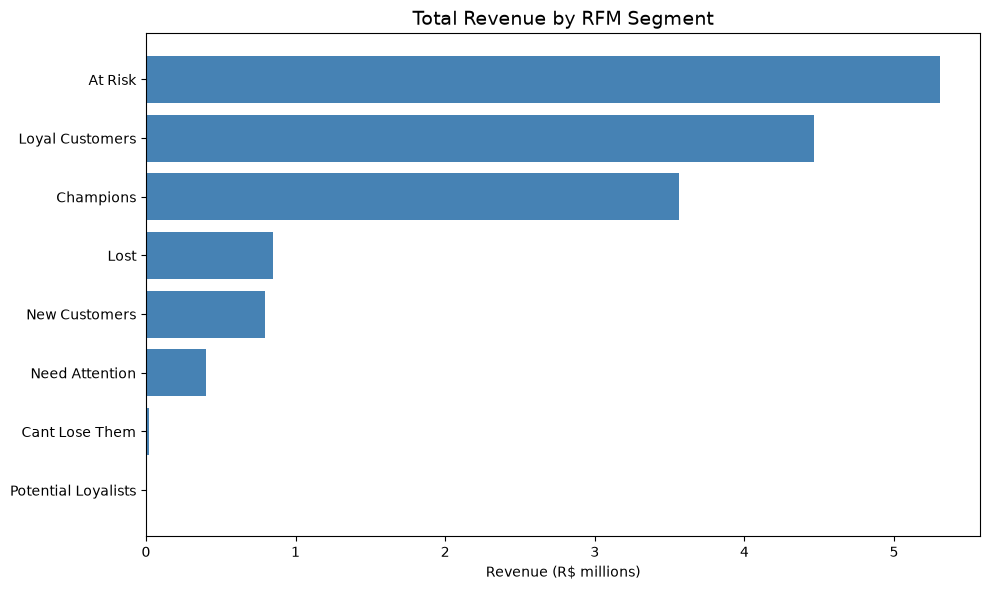

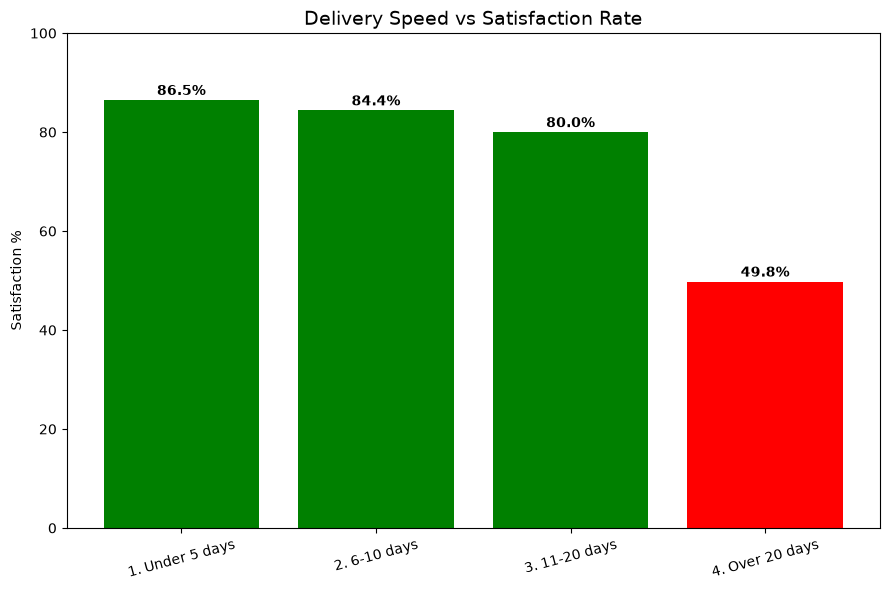

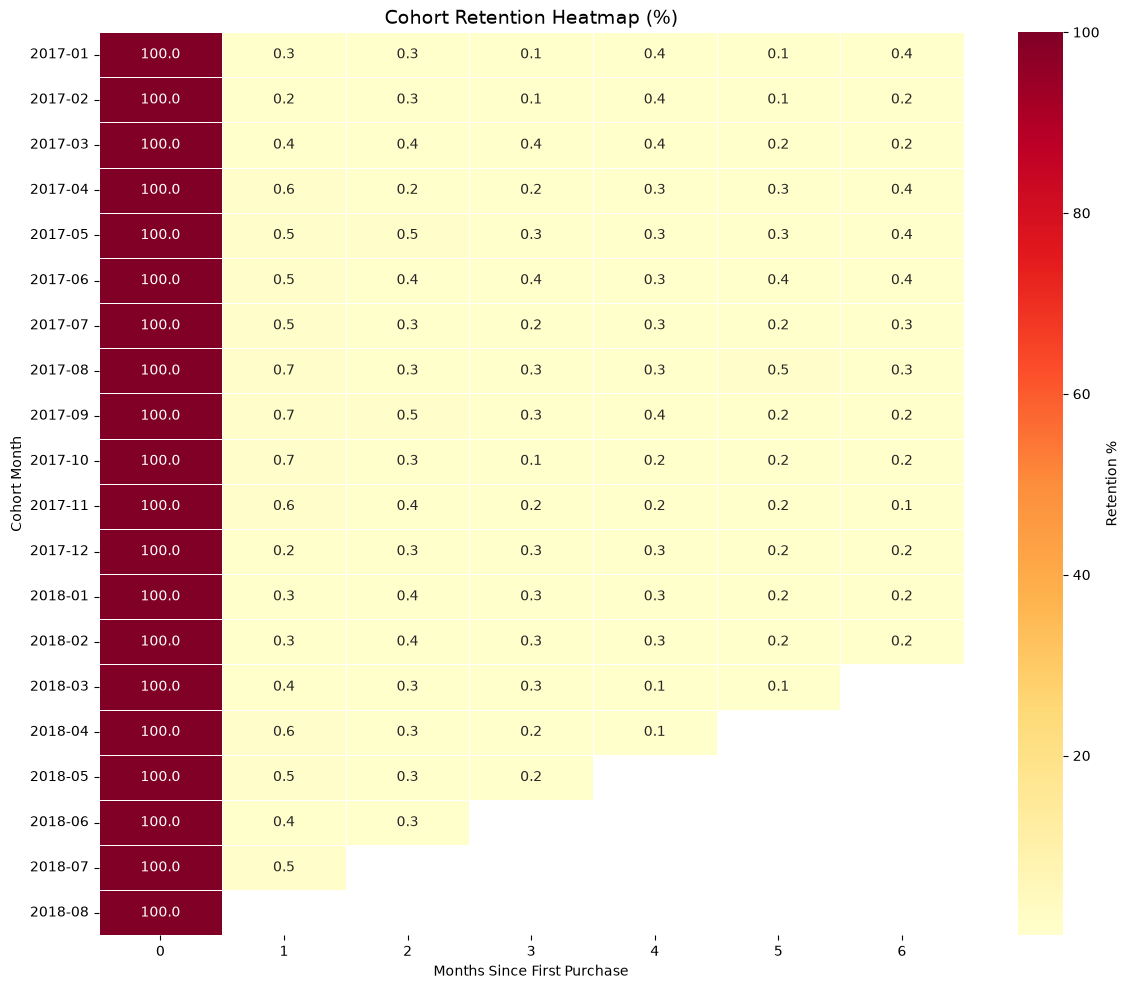

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. RFM Segments
fig, ax = plt.subplots(figsize=(10, 6))
rfm_sorted = rfm_df.sort_values('total_revenue_brl')
ax.barh(rfm_sorted['segment'], rfm_sorted['total_revenue_brl'] / 1e6, color='steelblue')
ax.set_title('Total Revenue by RFM Segment', fontsize=14)
ax.set_xlabel('Revenue (R$ millions)')
plt.tight_layout()
plt.savefig('da_ecommerce/rfm_segments.png', dpi=150, bbox_inches='tight')
plt.show()

# 2. Delivery vs Satisfaction
fig, ax = plt.subplots(figsize=(9, 6))
colors = ['green' if x >= 80 else 'orange' if x >= 60 else 'red'
          for x in delivery_df['satisfaction_pct']]
ax.bar(delivery_df['delivery_bucket'], delivery_df['satisfaction_pct'], color=colors)
ax.set_title('Delivery Speed vs Satisfaction Rate', fontsize=14)
ax.set_ylabel('Satisfaction %')
ax.set_ylim(0, 100)
ax.tick_params(axis='x', rotation=15)
for i, v in enumerate(delivery_df['satisfaction_pct']):
    ax.text(i, v + 1, f'{v}%', ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('da_ecommerce/delivery_satisfaction.png', dpi=150, bbox_inches='tight')
plt.show()

# 3. Cohort Retention Heatmap
fig, ax = plt.subplots(figsize=(12, 10))
cohort_pivot = cohort_df.pivot(index='cohort_month', columns='month_number', values='retention_pct')
cohort_pivot.index = cohort_pivot.index.astype(str).str[:7]
sns.heatmap(cohort_pivot, ax=ax, cmap='YlOrRd', annot=True, fmt='.1f',
            linewidths=0.5, cbar_kws={'label': 'Retention %'})
ax.set_title('Cohort Retention Heatmap (%)', fontsize=14)
ax.set_xlabel('Months Since First Purchase')
ax.set_ylabel('Cohort Month')
plt.tight_layout()
plt.savefig('da_ecommerce/cohort_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
rfm_df.to_json('da_ecommerce/data/clean/rfm_results.json', orient='records')
cohort_df.to_json('da_ecommerce/data/clean/cohort_results.json', orient='records')
delivery_df.to_json('da_ecommerce/data/clean/delivery_results.json', orient='records')
print('Exported.')

Exported.


In [12]:
cohort_export = cohort_df.copy()
cohort_export['cohort_month'] = cohort_export['cohort_month'].astype(str).str[:7]
cohort_export['month_number'] = cohort_export['month_number'].astype(str)
cohort_export.to_json('da_ecommerce/data/clean/cohort_results.json', orient='records')
print(cohort_export.dtypes)
print(cohort_export.head(3))

cohort_month               str
month_number               str
cohort_size              int64
returning_customers      int64
retention_pct          float64
dtype: object
  cohort_month month_number  cohort_size  returning_customers  retention_pct
0      2017-01            0          717                  717          100.0
1      2017-01            1          717                    2            0.3
2      2017-01            2          717                    2            0.3


In [13]:
## Monthly Revenue trend, Top 10 categories by Revenue

In [18]:
# Monthly revenue trend
monthly_sql = """
SELECT 
    DATE_TRUNC('month', order_purchase_timestamp)::DATE AS order_month,
    COUNT(order_id) AS order_count,
    ROUND(SUM(total_payment)::NUMERIC, 2) AS monthly_revenue
FROM fact_orders
GROUP BY order_month
ORDER BY order_month
"""

# Top 10 categories by revenue
category_sql = """
SELECT 
    p.category_en,
    COUNT(f.order_id) AS order_count,
    ROUND(SUM(f.total_payment)::NUMERIC, 2) AS total_revenue
FROM fact_orders f
JOIN bridge_order_items b ON f.order_id = b.order_id
JOIN dim_products p ON b.product_id = p.product_id
WHERE p.category_en IS NOT NULL
GROUP BY p.category_en
ORDER BY total_revenue DESC
LIMIT 10
"""

with engine.connect() as conn:
    monthly_df = pd.read_sql(text(monthly_sql), conn)
    category_df = pd.read_sql(text(category_sql), conn)

In [20]:
monthly_df_clean = monthly_df[monthly_df['order_month'].astype(str) >= '2017-01-01'].dropna()
monthly_df_clean['order_month'] = monthly_df_clean['order_month'].astype(str).str[:7]
monthly_df_clean.to_json('da_ecommerce/data/clean/monthly_revenue.json', orient='records')

category_df['category_en'] = category_df['category_en'].str.replace('_', ' ').str.title()
category_df.to_json('da_ecommerce/data/clean/category_revenue.json', orient='records')

display(monthly_df_clean.head())
display(category_df)

,order_month,order_count,monthly_revenue
3,2017-01,750,127545.67
4,2017-02,1651,271000.29
5,2017-03,2537,412085.69
6,2017-04,2303,390952.18
7,2017-05,3544,566486.93


,category_en,order_count,total_revenue
0,Bed Bath Table,10953,1692714.28
1,Health Beauty,9465,1620684.04
2,Computers Accessories,7641,1548480.87
3,Furniture Decor,8157,1393900.90
4,Watches Gifts,5856,1386787.16
5,Sports Leisure,8430,1349252.93
6,Housewares,6794,1069735.29
7,Auto,4137,833311.46
8,Garden Tools,4268,810614.93
9,Cool Stuff,3717,744487.07
